# Cassava Leaf Disease Classification: Summative Model Training & Evaluation
**Author:** Racheal Resty Akello  
**Links:**
* GitHub Repository: [rachealA924/Summative_modeltrainingandtraining](https://github.com/rachealA924/Summative_modeltrainingandtraining.git)
* Google Drive (Data, Models & Weights): [Google Drive Folder Link](https://drive.google.com/drive/folders/1pFZDtp62AhpwDWWG0D7KYr2bGlpKJadu?usp=sharing)
* Presentation Video: <INSERT_VIDEO_LINK_HERE>

**Problem:** classify cassava leaf photos into 5 classes (CBB, CBSD, CGM, CMD, Healthy) to support early disease detection.

**Data:** Kaggle "Cassava Leaf Disease Classification" (21,397 labelled images; accessed via the Kaggle API).

**Approach:** (1) classical ML (scikit-learn) on pretrained MobileNetV2 features, (2) deep learning (Keras, `tf.data`), 11 logged experiments (E1–E11), final evaluation on a held-out test set.

**Reproducibility:** seed 42 everywhere; run top to bottom on a Colab T4 GPU. Small run-to-run differences are normal on GPU.

## 1. Setup
Install dependencies and fix random seeds (Python, NumPy, TensorFlow) so splits and results can be reproduced. W&B is used for experiment tracking. Expected output: none (a few install lines).

In [1]:
# Cell 1: install + seeds
!pip install -q kaggle wandb
import os, random, numpy as np, tensorflow as tf
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

## 2. Data access
The data comes from a Kaggle competition, so the API token is stored as a Colab secret (never in the notebook). The zip (~5.8 GB) is downloaded to Colab's local disk because reading images from Drive is far slower. Expected output: `train.csv`, `train_images/`, and the label map in `/content/data`.

In [2]:
# Cell 2: Kaggle auth
import os
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

## 3. Data loading and exploratory analysis
Load the labels, map class numbers to disease names, and check the rubric requirements (≥ 20,000 rows, categorical target) and the class balance.

In [3]:
# Cell 3: download + unzip
!kaggle competitions download -c cassava-leaf-disease-classification -p /content/data
!cd /content/data && unzip -q cassava-leaf-disease-classification.zip
!ls /content/data

100% 5.76G/5.76G [01:02<00:00, 98.7MB/s]

cassava-leaf-disease-classification.zip  test_images	 train_images
label_num_to_disease_map.json		 test_tfrecords  train_tfrecords
sample_submission.csv			 train.csv


In [ ]:
import pandas as pd, json
df = pd.read_csv('/content/data/train.csv')
print(df.shape)                      # must be >= 20,000
print(df.head())
labels = json.load(open('/content/data/label_num_to_disease_map.json'))
df['disease'] = df['label'].astype(str).map(labels)
print(df['disease'].value_counts())
print(df['disease'].value_counts(normalize=True).round(3))

(21397, 2)
         image_id  label
0  1000015157.jpg      0
1  1000201771.jpg      3
2   100042118.jpg      1
3  1000723321.jpg      1
4  1000812911.jpg      3
disease
Cassava Mosaic Disease (CMD)           13158
Healthy                                 2577
Cassava Green Mottle (CGM)              2386
Cassava Brown Streak Disease (CBSD)     2189
Cassava Bacterial Blight (CBB)          1087
Name: count, dtype: int64
disease
Cassava Mosaic Disease (CMD)           0.615
Healthy                                0.120
Cassava Green Mottle (CGM)             0.112
Cassava Brown Streak Disease (CBSD)    0.102
Cassava Bacterial Blight (CBB)         0.051
Name: proportion, dtype: float64


In [ ]:
from PIL import Image
sizes, bad = set(), []
for f in df['image_id'].sample(500, random_state=SEED):
    try:
        with Image.open(f'/content/data/train_images/{f}') as im:
            sizes.add(im.size)
    except Exception as e:
        bad.append(f)
print("Sizes seen:", sizes, "| unreadable:", bad)

Sizes seen: {(800, 600)} | unreadable: []


**Findings:** The dataset contains 21,397 images across five classes. Class imbalance is substantial: CMD accounts for approximately 61.5% and CBB approximately 5.1%. Accuracy alone may therefore conceal weak minority-class performance, so macro-F1, per-class recall, and macro-AUC are also reported. In the inspected sample of 500 images, files were readable and had dimensions of 800 × 600 pixels. This sample check does not establish that every image in the dataset has the same dimensions or is free from corruption; resizing and input validation remain necessary.


## 4. Train / validation / test split
A stratified 70/15/15 split (seed 42) keeps class proportions identical in each part. The split is saved to CSV so every experiment uses exactly the same data. The test set is used only once, at the end. Expected: 14,977 / 3,210 / 3,210 images with matching class proportions.

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    d.to_csv(f'/content/{name}.csv', index=False)
    print(name, len(d), d['label'].value_counts(normalize=True).round(3).to_dict())

train 14977 {3: 0.615, 4: 0.12, 2: 0.112, 1: 0.102, 0: 0.051}
val 3210 {3: 0.615, 4: 0.121, 2: 0.112, 1: 0.102, 0: 0.051}
test 3210 {3: 0.615, 4: 0.12, 2: 0.112, 1: 0.102, 0: 0.051}


## 5. Input pipeline (`tf.data`)
Images are read, decoded, resized to 224×224, batched (64) and prefetched so the GPU is not starved. Shuffling uses a fixed seed on the training set only. Pixel scaling is applied inside each model's input step, to match what each model expects. Expected: a batch of shape (64, 224, 224, 3) and a GPU listed.

In [ ]:
import tensorflow as tf

IMG = 224
BATCH = 64
AUTOTUNE = tf.data.AUTOTUNE
IMG_DIR = '/content/data/train_images/'

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    return img, label

def make_ds(d, shuffle=False):
    paths = (IMG_DIR + d['image_id']).values
    ds = tf.data.Dataset.from_tensor_slices((paths, d['label'].values))
    if shuffle:
        ds = ds.shuffle(5000, seed=SEED)
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, shuffle=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

# Sanity checks
print("GPU:", tf.config.list_physical_devices('GPU'))
for x, y in train_ds.take(1):
    print("Batch images:", x.shape, "| labels:", y.shape, "| pixel range:", float(tf.reduce_min(x)), "-", float(tf.reduce_max(x)))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Batch images: (64, 224, 224, 3) | labels: (64,) | pixel range: 0.0 - 255.0


## 6. Experiment tracking
`log_experiment` scores each model on the validation set (accuracy, macro-F1, weighted-F1, macro-AUC), logs a run to W&B in offline mode, and appends a row to `experiment_results.csv`. This file is the source of the experiment table in the report.

In [ ]:
import os
os.environ["WANDB_MODE"] = "offline"   # rubric: use W&B offline mode
import wandb
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

CLASS_NAMES = ['CBB', 'CBSD', 'CGM', 'CMD', 'Healthy']   # labels 0-4
results = []   # every experiment is stored here

def log_experiment(name, approach, params, y_true, y_prob, notes=""):
    """Score one experiment on the VALIDATION set, log it to W&B, store it in `results`."""
    y_pred = np.argmax(y_prob, axis=1)
    metrics = {
        "accuracy":    accuracy_score(y_true, y_pred),
        "macro_f1":    f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
        "macro_auc":   roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"),
    }
    run = wandb.init(project="summative-cassava", name=name,
                     config={"approach": approach, **params}, reinit=True)
    wandb.log(metrics)
    wandb.finish()

    row = {"experiment": name, "approach": approach, **params, **metrics, "notes": notes}
    results.append(row)
    pd.DataFrame(results).to_csv("/content/experiment_results.csv", index=False)
    print({k: round(v, 4) for k, v in metrics.items()})

## 7. Feature extraction for the classical models
Classical algorithms cannot learn well from 150,528 raw pixels per image. A frozen, ImageNet-pretrained MobileNetV2 turns each image into 1,280 numbers, and scikit-learn models are trained on these.

 **Note:** this uses a pretrained model, so the classical pipeline is not fully independent of deep learning. Features are saved to avoid recomputation.

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Frozen pretrained network, used only as a feature extractor
extractor = MobileNetV2(weights="imagenet", include_top=False, pooling="avg",
                        input_shape=(IMG, IMG, 3))
extractor.trainable = False

def extract(d):
    ds = make_ds(d, shuffle=False)                       # no shuffle, so rows match d
    ds = ds.map(lambda x, y: (preprocess_input(x), y))   # scale pixels to [-1, 1]
    feats = extractor.predict(ds, verbose=1)
    return feats, d['label'].values

X_train, y_train = extract(train_df)
X_val,   y_val   = extract(val_df)
X_test,  y_test  = extract(test_df)

np.savez_compressed("/content/features.npz",
                    X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test)
print(X_train.shape, X_val.shape, X_test.shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
235/235 ━━━━━━━━━━━━━━━━━━━━ 65s 234ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 275ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 10s 195ms/step
(14977, 1280) (3210, 1280) (3210, 1280)


## 8. Classical ML experiments
**E1** Logistic Regression baseline. **E2** adds balanced class weights (changes one thing). **E3** Random Forest (different model family). Features are standardised with a scaler fit on the training set only, to avoid leakage.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Scale features (fit on TRAIN only, to avoid leaking validation information)
scaler = StandardScaler().fit(X_train)
Xtr, Xva = scaler.transform(X_train), scaler.transform(X_val)

# Experiment 1: Logistic Regression baseline
m = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)
m.fit(Xtr, y_train)
log_experiment("E1_logreg_baseline", "Classical ML",
               {"model": "LogisticRegression", "C": 1.0, "class_weight": "none"},
               y_val, m.predict_proba(Xva),
               notes="Baseline on MobileNetV2 features")

# Experiment 2: same model, but with class weights to counter the imbalance
m = LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced", random_state=SEED)
m.fit(Xtr, y_train)
log_experiment("E2_logreg_balanced", "Classical ML",
               {"model": "LogisticRegression", "C": 1.0, "class_weight": "balanced"},
               y_val, m.predict_proba(Xva),
               notes="Adds class weighting to help minority classes")

# Experiment 3: Random Forest
m = RandomForestClassifier(n_estimators=300, max_depth=None, n_jobs=-1, random_state=SEED)
m.fit(X_train, y_train)
log_experiment("E3_random_forest", "Classical ML",
               {"model": "RandomForest", "n_estimators": 300, "max_depth": "None"},
               y_val, m.predict_proba(X_val),
               notes="Non-linear tree ensemble, no scaling needed")

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


accuracy,▁
macro_auc,▁
macro_f1,▁
weighted_f1,▁
accuracy,0.69564
macro_auc,0.8398
macro_f1,0.49638
weighted_f1,0.68957


{'accuracy': 0.6956, 'macro_f1': 0.4964, 'weighted_f1': 0.6896, 'macro_auc': np.float64(0.8398)}


accuracy,▁
macro_auc,▁
macro_f1,▁
weighted_f1,▁
accuracy,0.6215
macro_auc,0.81128
macro_f1,0.47067
weighted_f1,0.64701


{'accuracy': 0.6215, 'macro_f1': 0.4707, 'weighted_f1': 0.647, 'macro_auc': np.float64(0.8113)}


accuracy,▁
macro_auc,▁
macro_f1,▁
weighted_f1,▁
accuracy,0.67477
macro_auc,0.85972
macro_f1,0.36193
weighted_f1,0.59389


{'accuracy': 0.6748, 'macro_f1': 0.3619, 'weighted_f1': 0.5939, 'macro_auc': np.float64(0.8597)}


In [ ]:
from sklearn.metrics import classification_report
from sklearn.ensemble import HistGradientBoostingClassifier

# Diagnostic: per-class results of E3 (the Random Forest still in memory as `m`)
rf_model = m
print(classification_report(y_val, rf_model.predict(X_val), target_names=CLASS_NAMES, digits=3))

# E4: Logistic Regression with STRONGER regularization (smaller C)
m = LogisticRegression(C=0.01, max_iter=1000, random_state=SEED)
m.fit(Xtr, y_train)
log_experiment("E4_logreg_C0.01", "Classical ML",
               {"model": "LogisticRegression", "C": 0.01, "class_weight": "none"},
               y_val, m.predict_proba(Xva),
               notes="Stronger L2 regularization vs E1 (1280 features, risk of overfitting)")

# E5: Gradient Boosting (histogram-based)
m = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, max_leaf_nodes=31,
                                   random_state=SEED)
m.fit(X_train, y_train)
log_experiment("E5_hist_gradient_boosting", "Classical ML",
               {"model": "HistGradientBoosting", "max_iter": 150, "learning_rate": 0.1, "max_leaf_nodes": 31},
               y_val, m.predict_proba(X_val),
               notes="Boosted trees, sequentially correcting errors")

# E6: Random Forest with balanced class weights and larger leaves
m = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                           n_jobs=-1, random_state=SEED)
m.fit(X_train, y_train)
log_experiment("E6_rf_balanced", "Classical ML",
               {"model": "RandomForest", "n_estimators": 300, "min_samples_leaf": 3, "class_weight": "balanced_subsample"},
               y_val, m.predict_proba(X_val),
               notes="E3 plus class weighting and leaf-size regularization")

              precision    recall  f1-score   support

         CBB      0.430     0.209     0.281       163
        CBSD      0.583     0.149     0.238       328
         CGM      0.783     0.050     0.094       358
         CMD      0.684     0.992     0.810      1974
     Healthy      0.654     0.274     0.386       387

    accuracy                          0.675      3210
   macro avg      0.627     0.335     0.362      3210
weighted avg      0.669     0.675     0.594      3210



accuracy,▁
macro_auc,▁
macro_f1,▁
weighted_f1,▁
accuracy,0.73302
macro_auc,0.88045
macro_f1,0.54607
weighted_f1,0.71981


{'accuracy': 0.733, 'macro_f1': 0.5461, 'weighted_f1': 0.7198, 'macro_auc': np.float64(0.8804)}


accuracy,▁
macro_auc,▁
macro_f1,▁
weighted_f1,▁
accuracy,0.7296
macro_auc,0.88705
macro_f1,0.51526
weighted_f1,0.6988


{'accuracy': 0.7296, 'macro_f1': 0.5153, 'weighted_f1': 0.6988, 'macro_auc': np.float64(0.887)}


accuracy,▁
macro_auc,▁
macro_f1,▁
weighted_f1,▁
accuracy,0.68816
macro_auc,0.86122
macro_f1,0.41648
weighted_f1,0.62194


{'accuracy': 0.6882, 'macro_f1': 0.4165, 'weighted_f1': 0.6219, 'macro_auc': np.float64(0.8612)}


**E4** stronger regularisation (C=0.01), **E5** histogram gradient boosting, **E6** Random Forest with class weights and larger leaves.

**Findings:** E4 beat E1 on every metric, which suggests E1 overfit 1,280 features. E3's per-class report shows the forest finds 99% of CMD but only 5% of CGM, so macro-F1 is low even though AUC is high. E5 had the best AUC (0.887); E4 had the best macro-F1 (0.546).

In [ ]:
pd.DataFrame(results)[["experiment", "accuracy", "macro_f1", "macro_auc"]].round(4)

,experiment,accuracy,macro_f1,macro_auc
0,E1_logreg_baseline,0.6956,0.4964,0.8398
1,E2_logreg_balanced,0.6215,0.4707,0.8113
2,E3_random_forest,0.6748,0.3619,0.8597
3,E4_logreg_C0.01,0.7330,0.5461,0.8804
4,E5_hist_gradient_boosting,0.7296,0.5153,0.8870
5,E6_rf_balanced,0.6882,0.4165,0.8612


## 9. Deep learning experiments (Keras)
**E7:** frozen MobileNetV2 backbone with a small trainable head (Dense 256, dropout 0.3, Adam 1e-3, early stopping on validation loss).

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

keras.utils.set_random_seed(SEED)
histories = {}

def prep(ds):
    return ds.map(lambda x, y: (preprocess_input(x), y),
                  num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

train_p, val_p, test_p = prep(train_ds), prep(val_ds), prep(test_ds)

def build_head_model(units=256, dropout=0.3, lr=1e-3):
    base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(IMG, IMG, 3))
    base.trainable = False
    inputs = keras.Input((IMG, IMG, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(5, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

# E7: frozen MobileNetV2 + dense head
model = build_head_model(units=256, dropout=0.3, lr=1e-3)
hist = model.fit(train_p, validation_data=val_p, epochs=8,
                 callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
histories["E7"] = hist.history
log_experiment("E7_keras_frozen_head", "Deep Learning",
               {"model": "MobileNetV2 frozen + Dense256", "dropout": 0.3, "lr": 1e-3, "epochs": 8, "batch": BATCH},
               y_val, model.predict(val_p), notes="First deep learning baseline, backbone frozen")

Epoch 1/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 69s 249ms/step - accuracy: 0.6892 - loss: 0.8594 - val_accuracy: 0.7259 - val_loss: 0.7458
Epoch 2/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 52s 220ms/step - accuracy: 0.7297 - loss: 0.7346 - val_accuracy: 0.7243 - val_loss: 0.7520
Epoch 3/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 51s 219ms/step - accuracy: 0.7506 - loss: 0.6908 - val_accuracy: 0.7386 - val_loss: 0.7131
Epoch 4/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 51s 216ms/step - accuracy: 0.7562 - loss: 0.6606 - val_accuracy: 0.7389 - val_loss: 0.7048
Epoch 5/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 51s 216ms/step - accuracy: 0.7678 - loss: 0.6316 - val_accuracy: 0.7318 - val_loss: 0.7358
Epoch 6/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 80s 209ms/step - accuracy: 0.7710 - loss: 0.6227 - val_accuracy: 0.7455 - val_loss: 0.7129
Epoch 7/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 49s 208ms/step - accuracy: 0.7795 - loss: 0.5980 - val_accuracy: 0.7480 - val_loss: 0.6916
Epoch 8/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 49s 208ms/step - accuracy: 0.7920 - loss: 0.5667 - 

accuracy,▁
macro_auc,▁
macro_f1,▁
weighted_f1,▁
accuracy,0.74798
macro_auc,0.9023
macro_f1,0.56615
weighted_f1,0.73395


{'accuracy': 0.748, 'macro_f1': 0.5661, 'weighted_f1': 0.7339, 'macro_auc': np.float64(0.9023)}


**Findings:** the best overall model by accuracy and AUC. Training loss falls steadily while validation loss flattens from epoch 4, a sign of mild overfitting.

**E8:** fine-tune the last 40 backbone layers at lr 1e-5.

In [ ]:
model.save("/content/E7_frozen_head.keras")      # keep E7 before we change the model

base = model.layers[1]                           # the MobileNetV2 backbone inside the model
print("Backbone layer:", base.name)
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False                      # keep early layers frozen
print("Trainable backbone layers:", sum(l.trainable for l in base.layers))

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist = model.fit(train_p, validation_data=val_p, epochs=6,
                 callbacks=[keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)])
histories["E8"] = hist.history

log_experiment("E8_keras_finetune_last40", "Deep Learning",
               {"model": "MobileNetV2 last 40 layers unfrozen + Dense256", "dropout": 0.3,
                "lr": 1e-5, "epochs": 6, "batch": BATCH},
               y_val, model.predict(val_p),
               notes="Builds on E7: unfreezes top backbone layers at low LR to adapt features to cassava")
model.save("/content/E8_finetuned.keras")

Backbone layer: mobilenetv2_1.00_224
Trainable backbone layers: 40
Epoch 1/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 110s 305ms/step - accuracy: 0.6464 - loss: 0.9718 - val_accuracy: 0.7430 - val_loss: 0.7283
Epoch 2/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 50s 211ms/step - accuracy: 0.7369 - loss: 0.7126 - val_accuracy: 0.7417 - val_loss: 0.8341
Epoch 3/6
235/235 ━━━━━━━━━━━━━━━━━━━━ 82s 211ms/step - accuracy: 0.7652 - loss: 0.6396 - val_accuracy: 0.7439 - val_loss: 0.8275
51/51 ━━━━━━━━━━━━━━━━━━━━ 16s 224ms/step


accuracy,▁
macro_auc,▁
macro_f1,▁
weighted_f1,▁
accuracy,0.74299
macro_auc,0.89939
macro_f1,0.56237
weighted_f1,0.73567


{'accuracy': 0.743, 'macro_f1': 0.5624, 'weighted_f1': 0.7357, 'macro_auc': np.float64(0.8994)}


**Findings:** no improvement over E7. Validation loss rose while training loss fell (overfitting). Early stopping restored the epoch-1 weights.

**E9:** E7 plus data augmentation (flips, rotation, zoom). Leaves have no fixed orientation, so these transformations are realistic.

In [ ]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

def build_aug_model(units=256, dropout=0.3, lr=1e-3):
    base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(IMG, IMG, 3))
    base.trainable = False
    aug = keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.15),
    ], name="augmentation")                     # active only during training
    inputs = keras.Input((IMG, IMG, 3))
    x = aug(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(5, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

# E9: E7 + data augmentation
model = build_aug_model()
hist = model.fit(train_p, validation_data=val_p, epochs=10,
                 callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
histories["E9"] = hist.history
log_experiment("E9_keras_frozen_augmented", "Deep Learning",
               {"model": "MobileNetV2 frozen + Dense256 + augmentation", "dropout": 0.3,
                "lr": 1e-3, "epochs": 10, "batch": BATCH, "augmentation": "flip+rot0.1+zoom0.15"},
               y_val, model.predict(val_p),
               notes="E7 plus data augmentation, to reduce overfitting seen in E7/E8")
model.save("/content/E9_frozen_augmented.keras")

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 66s 237ms/step - accuracy: 0.6816 - loss: 0.8933 - val_accuracy: 0.5302 - val_loss: 1.1978
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 73s 218ms/step - accuracy: 0.7119 - loss: 0.7962 - val_accuracy: 0.7162 - val_loss: 0.7915
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 49s 208ms/step - accuracy: 0.7169 - loss: 0.7687 - val_accuracy: 0.7234 - val_loss: 0.8003
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 51s 217ms/step - accuracy: 0.7237 - loss: 0.7567 - val_accuracy: 0.6336 - val_loss: 0.9368
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 60s 253ms/step - accuracy: 0.7259 - loss: 0.7499 - val_accuracy: 0.7075 - val_loss: 0.7796
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 49s 208ms/step - accuracy: 0.7289 - loss: 0.7446 - val_accuracy: 0.7243 - val_loss: 0.7709
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 65s 278ms/step - accuracy: 0.7357 - loss: 0.7241 - val_accuracy: 0.6916 - val_loss: 0.8316
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 50s 214ms/step - accuracy: 0.7375 - loss: 0

accuracy,▁
macro_auc,▁
macro_f1,▁
weighted_f1,▁
accuracy,0.7243
macro_auc,0.88368
macro_f1,0.56321
weighted_f1,0.72052


{'accuracy': 0.7243, 'macro_f1': 0.5632, 'weighted_f1': 0.7205, 'macro_auc': np.float64(0.8837)}


**Findings:** the train/validation gap closed, but accuracy fell, so bias increased. Validation accuracy was noisy between epochs.

In [ ]:
from google.colab import drive
import shutil, json, os
drive.mount('/content/drive')

BK = '/content/drive/MyDrive/cassava_backup'
os.makedirs(BK, exist_ok=True)
for f in ['experiment_results.csv', 'features.npz', 'train.csv', 'val.csv', 'test.csv',
          'E7_frozen_head.keras', 'E8_finetuned.keras', 'E9_frozen_augmented.keras']:
    if os.path.exists(f'/content/{f}'):
        shutil.copy(f'/content/{f}', BK)
shutil.copytree('/content/wandb', f'{BK}/wandb', dirs_exist_ok=True)
json.dump(histories, open(f'{BK}/histories.json', 'w'), default=float)
print(os.listdir(BK))

Mounted at /content/drive
['experiment_results.csv', 'features.npz', 'train.csv', 'val.csv', 'test.csv', 'E7_frozen_head.keras', 'E8_finetuned.keras', 'E9_frozen_augmented.keras', 'wandb', 'histories.json']


**E10:** E9 plus fine-tuning, combining the fixes for bias and variance.

In [ ]:
base = next(l for l in model.layers if 'mobilenet' in l.name)   # finds the backbone by name
print("Backbone layer:", base.name)
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
print("Trainable backbone layers:", sum(l.trainable for l in base.layers))

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist = model.fit(train_p, validation_data=val_p, epochs=8,
                 callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
histories["E10"] = hist.history

log_experiment("E10_keras_finetune_augmented", "Deep Learning",
               {"model": "MobileNetV2 last 40 layers unfrozen + Dense256 + augmentation", "dropout": 0.3,
                "lr": 1e-5, "epochs": 8, "batch": BATCH, "augmentation": "flip+rot0.1+zoom0.15"},
               y_val, model.predict(val_p),
               notes="Builds on E9: fine-tuning plus augmentation, combining the fixes for bias (E8) and variance (E9)")
model.save("/content/E10_finetune_augmented.keras")

Backbone layer: mobilenetv2_1.00_224
Trainable backbone layers: 40
Epoch 1/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 68s 234ms/step - accuracy: 0.6511 - loss: 0.9420 - val_accuracy: 0.7221 - val_loss: 0.8257
Epoch 2/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 52s 219ms/step - accuracy: 0.7137 - loss: 0.7888 - val_accuracy: 0.7103 - val_loss: 0.9518
Epoch 3/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 55s 233ms/step - accuracy: 0.7266 - loss: 0.7470 - val_accuracy: 0.7025 - val_loss: 0.9994
Epoch 4/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 78s 217ms/step - accuracy: 0.7383 - loss: 0.7209 - val_accuracy: 0.7187 - val_loss: 0.9223
51/51 ━━━━━━━━━━━━━━━━━━━━ 11s 179ms/step


accuracy,▁
macro_auc,▁
macro_f1,▁
weighted_f1,▁
accuracy,0.72212
macro_auc,0.88751
macro_f1,0.49183
weighted_f1,0.68132


{'accuracy': 0.7221, 'macro_f1': 0.4918, 'weighted_f1': 0.6813, 'macro_auc': np.float64(0.8875)}


**Findings:** worse than E9 (macro-F1 0.49). Validation loss climbed above 0.9 while training loss fell. Augmentation did not prevent the overfitting caused by unfreezing layers.

**E11:** E7 with softened class weights (square root of balanced weights). It tests whether the imbalance limits macro-F1.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

cw = compute_class_weight("balanced", classes=np.arange(5), y=train_df['label'].values)
class_weight = {i: float(w ** 0.5) for i, w in enumerate(cw)}   # softened weights
print("Class weights:", {CLASS_NAMES[i]: round(w, 2) for i, w in class_weight.items()})

model = build_head_model(units=256, dropout=0.3, lr=1e-3)
hist = model.fit(train_p, validation_data=val_p, epochs=8, class_weight=class_weight,
                 callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
histories["E11"] = hist.history

log_experiment("E11_keras_frozen_classweights", "Deep Learning",
               {"model": "MobileNetV2 frozen + Dense256", "dropout": 0.3, "lr": 1e-3, "epochs": 8,
                "batch": BATCH, "class_weight": "sqrt-balanced"},
               y_val, model.predict(val_p),
               notes="E7 plus softened class weights, to test whether imbalance limits macro-F1")
model.save("/content/E11_frozen_classweights.keras")

Class weights: {'CBB': 1.98, 'CBSD': 1.4, 'CGM': 1.34, 'CMD': 0.57, 'Healthy': 1.29}
Epoch 1/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 68s 230ms/step - accuracy: 0.6607 - loss: 0.9856 - val_accuracy: 0.7321 - val_loss: 0.7619
Epoch 2/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 71s 206ms/step - accuracy: 0.7123 - loss: 0.8401 - val_accuracy: 0.7262 - val_loss: 0.7489
Epoch 3/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 80s 197ms/step - accuracy: 0.7242 - loss: 0.7971 - val_accuracy: 0.7346 - val_loss: 0.7323
Epoch 4/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 46s 197ms/step - accuracy: 0.7395 - loss: 0.7598 - val_accuracy: 0.7346 - val_loss: 0.7276
Epoch 5/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 48s 205ms/step - accuracy: 0.7483 - loss: 0.7250 - val_accuracy: 0.7268 - val_loss: 0.7585
Epoch 6/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 82s 206ms/step - accuracy: 0.7594 - loss: 0.6992 - val_accuracy: 0.7305 - val_loss: 0.7501
Epoch 7/8
235/235 ━━━━━━━━━━━━━━━━━━━━ 80s 196ms/step - accuracy: 0.7636 - loss: 0.6859 - val_accuracy: 0.7277 - val_loss: 0.7518
51/51

accuracy,▁
macro_auc,▁
macro_f1,▁
weighted_f1,▁
accuracy,0.73458
macro_auc,0.89768
macro_f1,0.57979
weighted_f1,0.73181


{'accuracy': 0.7346, 'macro_f1': 0.5798, 'weighted_f1': 0.7318, 'macro_auc': np.float64(0.8977)}


**Findings:** macro-F1 rose to 0.580 (best on validation) while accuracy fell slightly. Training and validation curves stay close.

## 10. Model selection and saving
Models were selected using **validation** macro-F1: E4 (classical) and E11 (deep). They are saved as `.joblib` and `.h5`/`.keras`, and everything is backed up to Drive.

In [ ]:
import joblib, shutil, os, json
from sklearn.pipeline import make_pipeline
from google.colab import drive

# 1) Full results table so far
print(pd.DataFrame(results)[["experiment", "accuracy", "macro_f1", "macro_auc"]].round(4).to_string(index=False))

# 2) Re-train the best classical model (E4) as one pipeline and save it
best_classical = make_pipeline(StandardScaler(),
                               LogisticRegression(C=0.01, max_iter=1000, random_state=SEED))
best_classical.fit(X_train, y_train)
chk = best_classical.predict_proba(X_val)
print("E4 re-check macro_f1:", round(f1_score(y_val, chk.argmax(1), average="macro"), 4))
joblib.dump(best_classical, "/content/best_classical_E4_logreg.joblib")

# 3) Save the best deep model (E11, still in memory as `model`)
model.save("/content/best_deep_E11.keras")
model.save("/content/best_deep_E11.h5")

# 4) Back up everything to Drive
drive.mount('/content/drive')
BK = '/content/drive/MyDrive/cassava_backup'
os.makedirs(BK, exist_ok=True)
for f in ['experiment_results.csv', 'features.npz', 'train.csv', 'val.csv', 'test.csv',
          'best_classical_E4_logreg.joblib', 'best_deep_E11.keras', 'best_deep_E11.h5',
          'E7_frozen_head.keras', 'E8_finetuned.keras', 'E9_frozen_augmented.keras',
          'E10_finetune_augmented.keras', 'E11_frozen_classweights.keras']:
    if os.path.exists(f'/content/{f}'):
        shutil.copy(f'/content/{f}', BK)
shutil.copytree('/content/wandb', f'{BK}/wandb', dirs_exist_ok=True)
json.dump(histories, open(f'{BK}/histories.json', 'w'), default=float)
print(sorted(os.listdir(BK)))

                   experiment  accuracy  macro_f1  macro_auc
           E1_logreg_baseline    0.6956    0.4964     0.8398
           E2_logreg_balanced    0.6215    0.4707     0.8113
             E3_random_forest    0.6748    0.3619     0.8597
              E4_logreg_C0.01    0.7330    0.5461     0.8804
    E5_hist_gradient_boosting    0.7296    0.5153     0.8870
               E6_rf_balanced    0.6882    0.4165     0.8612
         E7_keras_frozen_head    0.7480    0.5661     0.9023
     E8_keras_finetune_last40    0.7430    0.5624     0.8994
    E9_keras_frozen_augmented    0.7243    0.5632     0.8837
 E10_keras_finetune_augmented    0.7221    0.4918     0.8875
E11_keras_frozen_classweights    0.7346    0.5798     0.8977
E4 re-check macro_f1: 0.5461


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['E10_finetune_augmented.keras', 'E11_frozen_classweights.keras', 'E7_frozen_head.keras', 'E8_finetuned.keras', 'E9_frozen_augmented.keras', 'best_classical_E4_logreg.joblib', 'best_deep_E11.h5', 'best_deep_E11.keras', 'experiment_results.csv', 'features.npz', 'histories.json', 'test.csv', 'train.csv', 'val.csv', 'wandb']


## 11. Learning curves
Training vs validation loss and accuracy for E7–E11. E8 and E10 show only their fine-tuning phase.

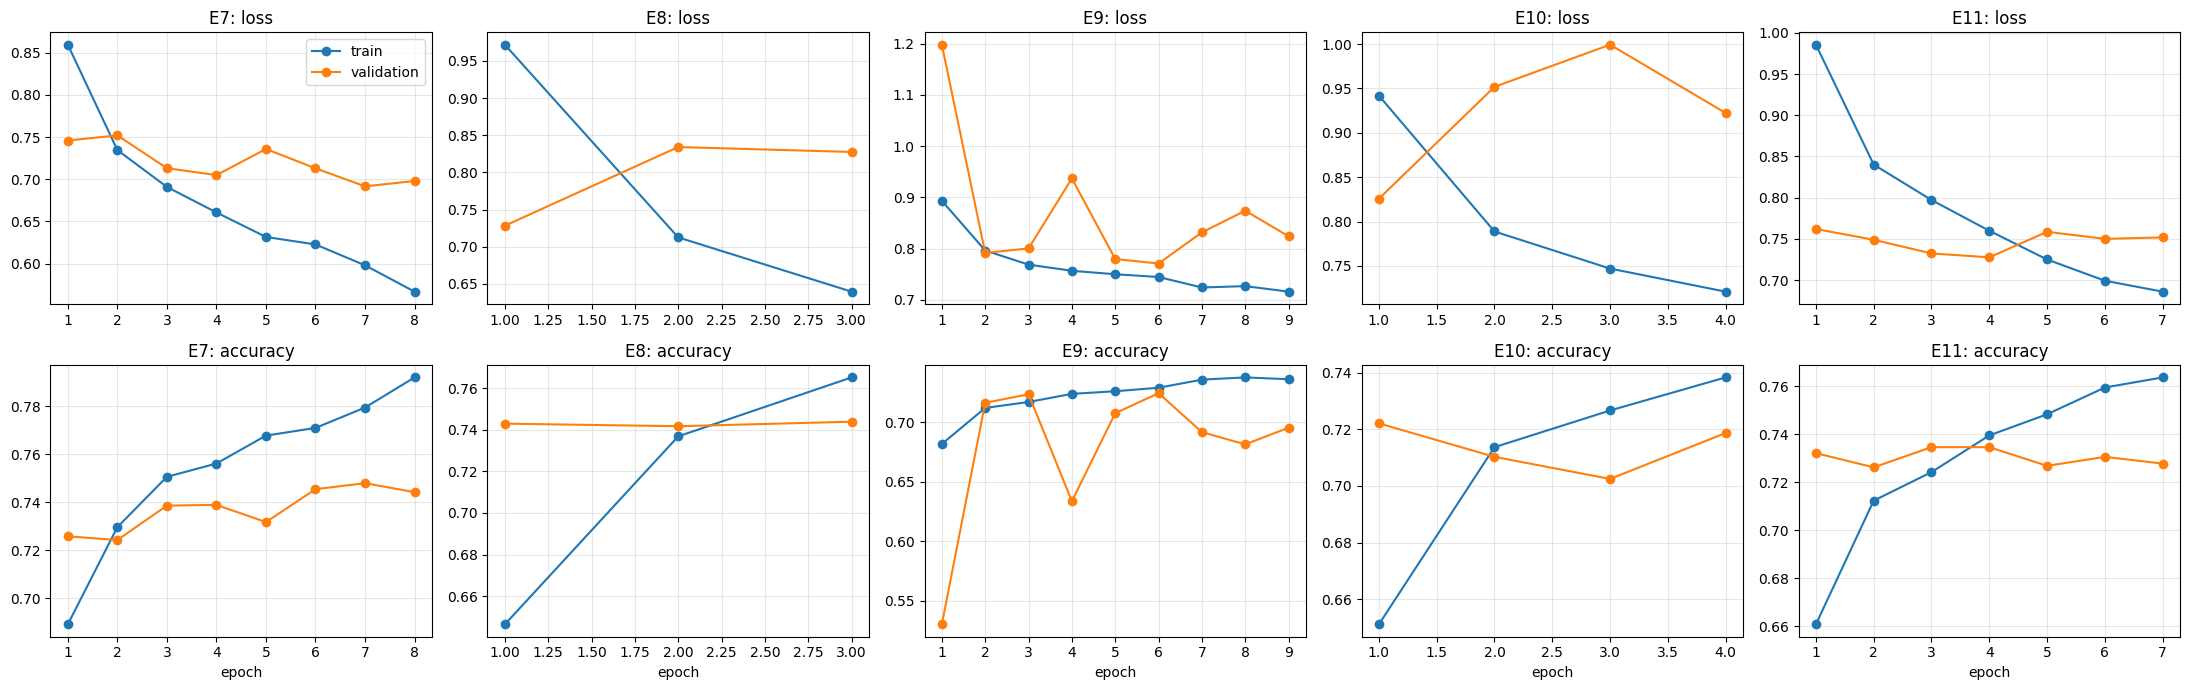

In [ ]:
import matplotlib.pyplot as plt
os.makedirs('/content/figures', exist_ok=True)

exps = ["E7", "E8", "E9", "E10", "E11"]
fig, axes = plt.subplots(2, len(exps), figsize=(22, 7))
for j, e in enumerate(exps):
    h = histories[e]
    ep = range(1, len(h['loss']) + 1)
    axes[0, j].plot(ep, h['loss'], marker='o', label='train')
    axes[0, j].plot(ep, h['val_loss'], marker='o', label='validation')
    axes[0, j].set_title(f"{e}: loss")
    axes[1, j].plot(ep, h['accuracy'], marker='o', label='train')
    axes[1, j].plot(ep, h['val_accuracy'], marker='o', label='validation')
    axes[1, j].set_title(f"{e}: accuracy")
    axes[1, j].set_xlabel("epoch")
    for r in (0, 1):
        axes[r, j].grid(alpha=0.3)
axes[0, 0].legend()
plt.tight_layout()
plt.savefig('/content/figures/learning_curves.png', dpi=200)
plt.show()

**Interpretation:** The E7–E11 learning curves allow comparison of training and validation behavior, but the degree of overfitting should be assessed separately for each experiment. E9 uses augmentation with a **frozen** MobileNetV2 backbone; E8 and E10 include fine-tuning. Any widening gap between training and validation performance suggests a generalization concern rather than proving its cause. E11 uses a frozen backbone with softened class weights, and its validation macro-F1 was the strongest among the reported deep-learning runs. Its performance should be interpreted alongside per-class recall and test-set results.


## 12. Final evaluation on the test set
Run once, with the two selected models. Reported: accuracy, macro/weighted F1, macro-AUC, per-class precision/recall, row-normalised confusion matrices, one-vs-rest ROC curves.

51/51 ━━━━━━━━━━━━━━━━━━━━ 20s 264ms/step
                             model  accuracy  macro_f1  weighted_f1  macro_auc
E4 Logistic Regression (classical)    0.7318    0.5491       0.7200     0.8809
       E11 MobileNetV2 head (deep)    0.7283    0.5713       0.7214     0.8960

 E4 Logistic Regression (classical)
              precision    recall  f1-score   support

         CBB      0.467     0.344     0.396       163
        CBSD      0.552     0.471     0.508       329
         CGM      0.546     0.416     0.472       358
         CMD      0.833     0.911     0.870      1974
     Healthy      0.505     0.492     0.499       386

    accuracy                          0.732      3210
   macro avg      0.580     0.527     0.549      3210
weighted avg      0.714     0.732     0.720      3210


 E11 MobileNetV2 head (deep)
              precision    recall  f1-score   support

         CBB      0.483     0.613     0.541       163
        CBSD      0.700     0.362     0.477       329
  

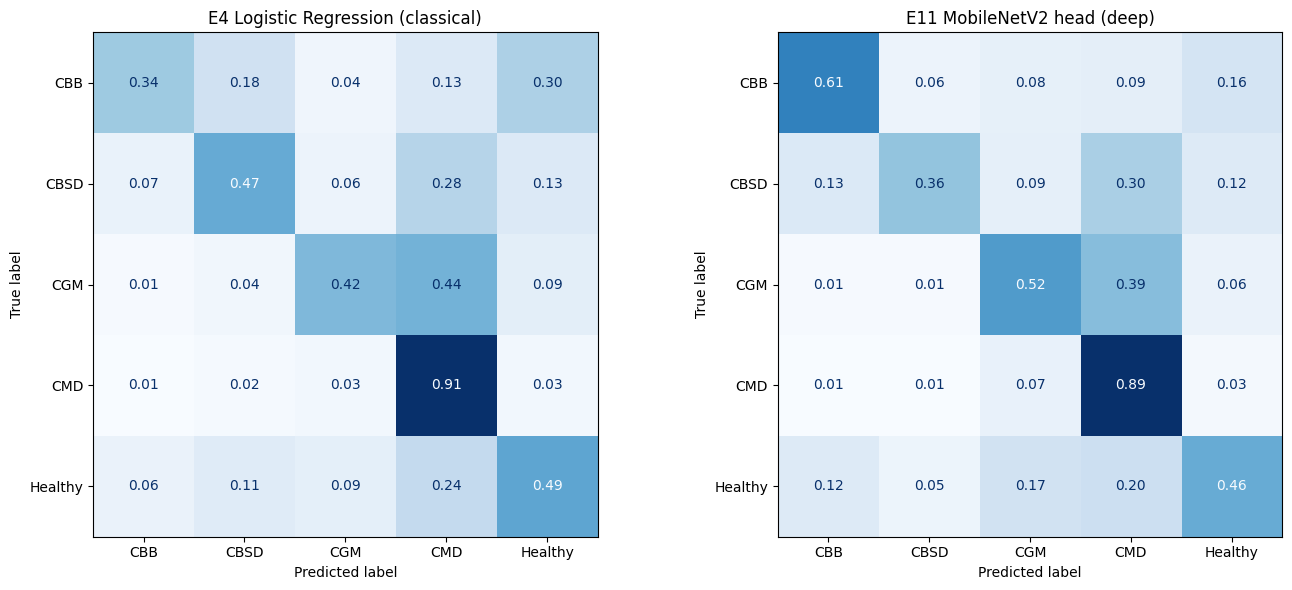

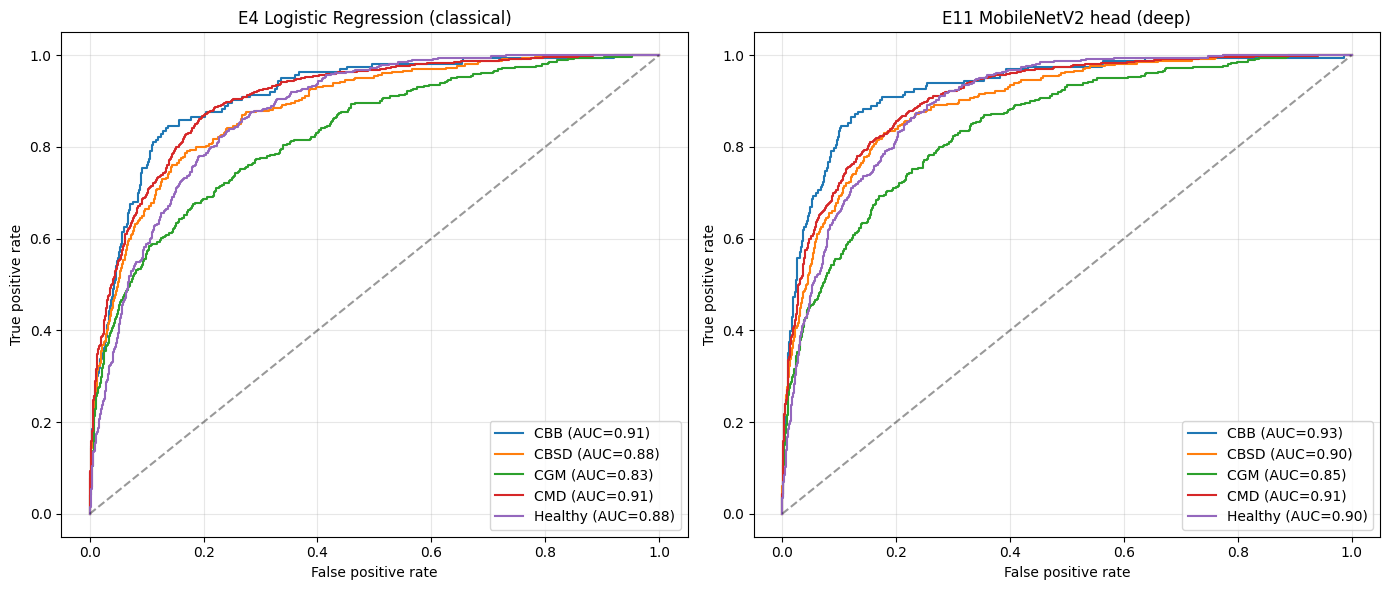

'/content/drive/MyDrive/cassava_backup/test_results.csv'

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, ConfusionMatrixDisplay
from sklearn.preprocessing import label_binarize

# Load the saved best models and score the TEST set
clf = joblib.load('/content/best_classical_E4_logreg.joblib')
dl  = keras.models.load_model('/content/best_deep_E11.keras')
probs = {
    "E4 Logistic Regression (classical)": clf.predict_proba(X_test),
    "E11 MobileNetV2 head (deep)":        dl.predict(test_p),
}

# Test-set metrics table
rows = []
for name, p in probs.items():
    pred = p.argmax(1)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "macro_f1": f1_score(y_test, pred, average="macro"),
                 "weighted_f1": f1_score(y_test, pred, average="weighted"),
                 "macro_auc": roc_auc_score(y_test, p, multi_class="ovr", average="macro")})
test_results = pd.DataFrame(rows).round(4)
test_results.to_csv('/content/test_results.csv', index=False)
print(test_results.to_string(index=False))

# Per-class precision / recall / F1
for name, p in probs.items():
    print("\n", name)
    print(classification_report(y_test, p.argmax(1), target_names=CLASS_NAMES, digits=3))

# Confusion matrices (row-normalized = per-class recall)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, p) in zip(axes, probs.items()):
    cm = confusion_matrix(y_test, p.argmax(1), normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig('/content/figures/confusion_matrices.png', dpi=200); plt.show()

# One-vs-rest ROC curves
Y = label_binarize(y_test, classes=np.arange(5))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, p) in zip(axes, probs.items()):
    for i, c in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(Y[:, i], p[:, i])
        ax.plot(fpr, tpr, label=f"{c} (AUC={auc(fpr, tpr):.2f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax.set_title(name); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('/content/figures/roc_curves.png', dpi=200); plt.show()

# Back up the new outputs
shutil.copytree('/content/figures', f'{BK}/figures', dirs_exist_ok=True)
shutil.copy('/content/test_results.csv', BK)

**Findings:** On the held-out test set, E11 achieved macro-F1 of approximately 0.571 and E4 approximately 0.549. These results are broadly consistent with the reported validation ranking, but similar validation and test scores do **not** prove that model selection avoided overfitting. E11 improved CBB recall from approximately 0.34 (E4) to 0.61, while both models frequently predicted CMD for some CGM, CBSD, and Healthy images. The confusion matrices and per-class metrics should be used to assess these errors.


## 13. Conclusion and limitations
Frozen pretrained features with a small head gave the best results; fine-tuning overfit. The main limits are the class imbalance and the frozen-feature ceiling. Future work: focal loss or threshold tuning, a larger backbone, more minority-class data.

## Critical Analysis: Bias–Variance Trade-Offs and Error Analysis

### 1. Model Complexity and Generalization

* **Traditional machine learning (E1–E6):** Logistic Regression (E4) was selected on validation macro-F1. The tested ensemble models provide nonlinear alternatives, but the recorded comparison does not establish that they significantly reduced bias. Differences in validation performance may reflect representation, regularization, or model capacity; training–validation gaps and controlled experiments are needed to distinguish these explanations.
* **Deep learning (E7–E11):** E7, E9, and E11 use a frozen MobileNetV2 backbone, while E8 and E10 explore fine-tuning. E9 adds augmentation without unfreezing the backbone. Fine-tuning increases trainable capacity but does not automatically improve generalization. E11 combines a frozen backbone with softened class weights; the observed validation and test metrics provide evidence of its practical trade-offs, not proof of a specific bias–variance mechanism.

### 2. Error Analysis and Class Imbalance

* **Majority-class effects:** CMD is much more common than CBB. Consequently, accuracy can appear strong even when recall for minority diseases is limited. The per-class classification reports and row-normalized confusion matrices provide a more informative assessment.
* **Mitigation experiments:** E10 tests fine-tuning with augmentation; **E11 alone** applies softened (square-root balanced) class weights. The experiments therefore test different interventions and should not be described as a single class-weighting strategy. E11 achieved the highest reported validation macro-F1 and improved CBB recall on the test set compared with E4, though errors remain for other classes.

### 3. Limitations and Next Steps

The dataset's imbalance and potential differences between ImageNet features and cassava leaf imagery limit generalization. Further work could compare repeated random seeds, tune decision thresholds on validation data, examine minority-class errors manually, and evaluate on independently collected images. These are proposed follow-ups, not results established by this notebook.


In [4]:
import os, shutil
from google.colab import drive
drive.mount('/content/drive')

BK = '/content/drive/MyDrive/cassava_backup'
FINAL = '/content/drive/MyDrive/Cassava_Summative_Deliverables'
os.makedirs(f'{FINAL}/models', exist_ok=True)
os.makedirs(f'{FINAL}/results', exist_ok=True)

for f in ['best_classical_E4_logreg.joblib', 'best_deep_E11.h5', 'best_deep_E11.keras']:
    shutil.copy(f'{BK}/{f}', f'{FINAL}/models')
for f in ['experiment_results.csv', 'test_results.csv', 'train.csv', 'val.csv', 'test.csv', 'histories.json']:
    shutil.copy(f'{BK}/{f}', f'{FINAL}/results')
shutil.copytree(f'{BK}/figures', f'{FINAL}/results/figures', dirs_exist_ok=True)
shutil.copytree(f'{BK}/wandb', f'{FINAL}/results/wandb_offline_logs', dirs_exist_ok=True)

zip_path = '/content/data/cassava-leaf-disease-classification.zip'
if os.path.exists(zip_path):
    shutil.copy(zip_path, FINAL)
else:
    print("Raw zip missing: run the first three cells (download) and re-run this cell.")
print(sorted(os.listdir(FINAL)))

Mounted at /content/drive
['cassava-leaf-disease-classification.zip', 'models', 'results']
